In [23]:
import numpy as np

# Ground Truth: A hard 'One-Hot' encoded class probability vector 
# (Represents Class 0 as the true label)
p_true = np.array([1.0, 0.0, 0.0])

# Optimization Path Array: Shifting logits (raw model scores) 
# As 'w' scales up, the model learns and outputs higher confidence for Class 0
weights = np.linspace(-2.0, 5.0, 100)

print(f"Generated {len(weights)} multi-class optimization testing vectors.")

Generated 100 multi-class optimization testing vectors.


In [24]:
from numpy import cross, log2


def softmax(logits):
    # e^a / sum(e^a)
    exp_logits = np.exp(logits)
    return exp_logits / np.sum(exp_logits)


def cross_entropy(p, q):
    q = np.clip(q, 1e-15, 1 - 1e-15)

    return -np.sum(p * np.log2(q))

def kl_divergence(p, q):
    p = np.clip(p, 1e-15, 1 - 1e-15)
    q = np.clip(q, 1e-15, 1 - 1e-15)
    return np.sum(p * log2(p / q))


cross_entropy_test = cross_entropy([0.9, 0.1], [0.8, 0.2])
kl_test = kl_divergence([0.9, 0.1], [0.8, 0.2])

cross_entropy_test, kl_test

(np.float64(0.5219280948873624), np.float64(0.052932501298081136))

[5.05606457 4.95722961 4.85861943 4.76024937 4.66213572 4.56429578
 4.46674792 4.36951159 4.27260742 4.17605723 4.07988407 3.98411232
 3.88876767 3.7938772  3.69946938 3.60557415 3.5122229  3.41944851
 3.32728538 3.23576937 3.14493787 3.05482973 2.96548522 2.87694602
 2.78925513 2.70245679 2.61659641 2.53172039 2.44787605 2.36511142
 2.28347508 2.20301596 2.1237831  2.04582542 1.96919144 1.89392902
 1.82008505 1.74770512 1.67683326 1.60751155 1.53977983 1.47367538
 1.40923262 1.34648277 1.28545359 1.22616916 1.16864961 1.11291094
 1.05896487 1.00681872 0.95647534 0.90793307 0.8611858  0.81622295
 0.77302966 0.73158688 0.69187157 0.65385693 0.61751262 0.58280506
 0.5496977  0.51815135 0.48812449 0.45957359 0.43245344 0.40671746
 0.38231803 0.35920677 0.33733484 0.31665321 0.2971129  0.27866521
 0.26126195 0.24485559 0.22939947 0.21484791 0.20115634 0.18828143
 0.17618113 0.1648148  0.15414319 0.14412853 0.13473455 0.12592646
 0.11767098 0.10993631 0.10269214 0.09590961 0.08956126 0.0836

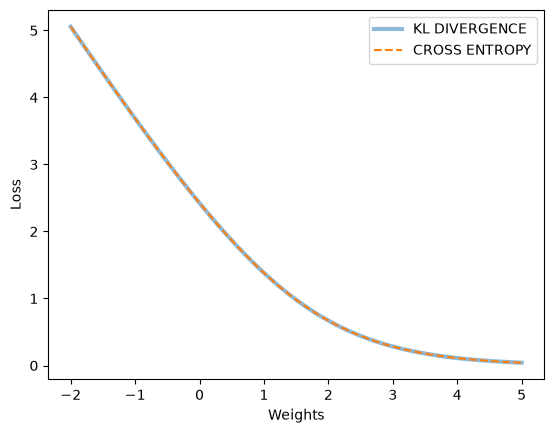

In [25]:
ce_losses = []
kl_losses = []

for w in weights:
    logits = np.array([w, 1, 0.5])
    q_pred = softmax(logits)

    ce_loss = cross_entropy(p_true, q_pred)
    kl_loss = kl_divergence(p_true, q_pred)
    ce_losses.append(ce_loss)
    kl_losses.append(kl_loss)

ce_losses = np.array(ce_losses)
kl_losses = np.array(kl_losses)

print(ce_losses)
print(kl_losses)

from turtle import width

import matplotlib.pyplot as plt

plt.xlabel("Weights")
plt.ylabel("Loss")
plt.plot(weights, kl_losses, label="KL DIVERGENCE", linewidth=3, alpha=0.5)
plt.plot(weights, ce_losses, label="CROSS ENTROPY", linestyle="--", linewidth=1.5)
plt.legend()
plt.show()